In [4]:
%pip install pandas numpy matplotlib seaborn openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import os 

print("All libraries is imported successfully")

All libraries is imported successfully


In [6]:
df=pd.read_excel("F:/WeIntern_datascience_1/data/Online Retail_raw.xlsx")

In [7]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [8]:
df.to_excel("online_retail_cleaned.xlsx", index=False)

In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
df.shape

(541909, 8)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [12]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [13]:
missing_values = df.isnull().sum()

In [14]:
print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [15]:
# calculate missing value percentage
missing_percentage = (df.isnull().sum()/len(df))*100

In [16]:
missing_percentage

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [17]:
# Create a Summary Report DataFrame
missing_report = pd.DataFrame({
    "missing_values":missing_values,
    "missing percentage":missing_percentage
})

In [18]:
missing_report

,missing_values,missing percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [19]:
#checking for duplicate record
duplicate_count = df.duplicated().sum()

In [20]:
duplicate_count

np.int64(5268)

In [21]:
# Display first 10 duplicate records
df[df.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [22]:
# check for negative or zero quantity
print("Negative Quantity",(df["Quantity"]<0).sum()),
print("zero Quantity",(df["Quantity"]==0).sum())
      

Negative Quantity 10624
zero Quantity 0


In [23]:
# check for negative or zero Price
print("Negative unitPrice",(df["UnitPrice"]<0).sum()),
print("Zero UnitPrice",(df["UnitPrice"]==0).sum())

Negative unitPrice 2
Zero UnitPrice 2515


In [24]:
#check cancelled invoice
cancelled_invoice= df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled Invoice Records:",cancelled_invoice.sum())
      

Cancelled Invoice Records: 9288


In [25]:
# copy file for cleaning
df_clean = df.copy()

In [26]:
#drop rows customerID or Descreption 
df_clean =df_clean.dropna(subset=["CustomerID","Description"])

In [27]:
#remove duplicate rows
df_clean=df_clean.drop_duplicates()

In [28]:
#create total revenue column
df_clean["TotalRevenue"]=df_clean["Quantity"]*df_clean["UnitPrice"]

In [29]:
# save clean data set
df_clean.to_excel("cleaned_online_retail.xlsx",index=False)
print(f"Cleaned Dataset Shape: {df_clean.shape}")
print("Cleaned dataset successfully saved as 'cleaned_online_retail.xlsx'!")

Cleaned Dataset Shape: (401604, 9)
Cleaned dataset successfully saved as 'cleaned_online_retail.xlsx'!


In [205]:
df_clean.to_excel("cleaned_online_retail_data.xlsx",index=False)

In [206]:
df_clean


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [32]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     401604 non-null  object        
 1   StockCode     401604 non-null  object        
 2   Description   401604 non-null  object        
 3   Quantity      401604 non-null  int64         
 4   InvoiceDate   401604 non-null  datetime64[ns]
 5   UnitPrice     401604 non-null  float64       
 6   CustomerID    401604 non-null  float64       
 7   Country       401604 non-null  object        
 8   TotalRevenue  401604 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 30.6+ MB


In [33]:
df_clean.isnull().sum()

InvoiceNo       0
StockCode       0
Description     0
Quantity        0
InvoiceDate     0
UnitPrice       0
CustomerID      0
Country         0
TotalRevenue    0
dtype: int64

In [34]:
df_clean.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue'],
      dtype='object')

In [35]:
df_clean.duplicated().sum()

np.int64(0)

In [36]:
#Sales Data Analysis

In [37]:
#total revenue
total_revenue=df_clean["TotalRevenue"].sum()

In [38]:
total_revenue

np.float64(8278519.424)

In [39]:
total_order = df_clean["InvoiceNo"].nunique()
total_order

22190

In [40]:
total_unit_sold= df_clean["Quantity"].sum()
total_unit_sold

np.int64(4892851)

In [41]:
Avg_order_value=total_revenue/total_unit_sold
Avg_order_value

np.float64(1.6919622984636156)

In [42]:
Top_Category = (df_clean.groupby("Description")["TotalRevenue"].sum()
.sort_values(ascending=False))

In [43]:
#Category with highest sales contribution
Top_Category.head(10)

Description
REGENCY CAKESTAND 3 TIER              132567.70
WHITE HANGING HEART T-LIGHT HOLDER     93767.80
JUMBO BAG RED RETROSPOT                83056.52
PARTY BUNTING                          67628.43
POSTAGE                                66710.24
ASSORTED COLOUR BIRD ORNAMENT          56331.91
RABBIT NIGHT LIGHT                     51042.84
CHILLI LIGHTS                          45915.41
PAPER CHAIN KIT 50'S CHRISTMAS         41423.78
PICNIC BASKET WICKER 60 PIECES         39619.50
Name: TotalRevenue, dtype: float64

In [44]:
#Product with highest revenue or demand
Best_Product=Top_Category.head(1)

In [45]:
Best_Product

Description
REGENCY CAKESTAND 3 TIER    132567.7
Name: TotalRevenue, dtype: float64

In [46]:
#trends
#Monthly or weekly sales growth.
df_sale=df_clean.copy()

In [47]:
df_sale

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [48]:
# Remove cancelled invoices
df_sale=df_sale[
    ~df_sale["InvoiceNo"].astype(str).str.startswith("C")
    ]

In [49]:
df_sale

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [50]:
#positive Quantity and price
df_sale=df_sale[
    (df_sale["Quantity"]>0)&
    (df_sale["UnitPrice"]>0)
    ]

In [51]:
df_sale

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [52]:
#revenue
df_sale["RevenueTotal"]=(
    df_sale["Quantity"]*df_sale["UnitPrice

SyntaxError: unterminated string literal (detected at line 3) (26819479.py, line 3)

In [53]:
# create on independant copy
df_sale = df_clean[df_clean ["Quantity"] > 0
].copy()

In [54]:
df_sale["RevenueTotal"] = (
    df_sale["Quantity"] * df_sale["UnitPrice"]
)

In [55]:
print(df_sale.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalRevenue  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom         15.30   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom         20.34   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom         22.00   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom         20.34   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom         20.34   

   RevenueTotal  
0         15.30  
1         20.34  
2         22.00  
3         20.34  
4       

In [56]:
df_sale[["Quantity", "UnitPrice", "RevenueTotal"]].head(10)

,Quantity,UnitPrice,RevenueTotal
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [57]:
print("sales records:  ",len(df_sale))

sales records:   392732


In [58]:
df_sale

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue,RevenueTotal
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34
...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,16.60


In [59]:
df_clean

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [60]:
#Monthly sales growth
#calcuate revenue month wise  ---> convert invocedate into datetime
df_sale["InvoiceDate"] = pd.to_datetime(
    df_sale["InvoiceDate"]
)


In [61]:
#Extract month ---> o group all sales transactions  to the same month.
#.dt allows us to access date-related properties.
#.to_period("M") extracts the year and month from the date.
#"M" means monthly frequency.
df_sale["Month"]= (
    df_sale["InvoiceDate"].dt.to_period("M")
)

In [62]:
#Calculate monthly revenue --->To identify how much revenue  generated every month.
monthly_sale=(
    df_sale.groupby("Month")["RevenueTotal"]
    .sum()
)

In [63]:
monthly_sale

Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: RevenueTotal, dtype: float64

In [64]:
#pct_change() calculates the percentage change compared with the previous month.
# formula --> current-previous/previous*100
monthly_growth=monthly_sale.pct_change() * 100

In [65]:
monthly_growth

Month
2010-12          NaN
2011-01    -0.406965
2011-02   -21.477928
2011-03    33.176831
2011-04   -21.159954
2011-05    44.618333
2011-06    -2.555395
2011-07    -9.254377
2011-08     7.527701
2011-09    47.611003
2011-10     8.935850
2011-11    11.641388
2011-12   -55.268299
Freq: M, Name: RevenueTotal, dtype: float64

In [66]:
monthly_report = pd.DataFrame(
    {
        "Revenue":monthly_sale,
        "Growth_percentage":monthly_growth
    }
)

In [67]:
monthly_report

,Revenue,Growth_percentage
Month,,
2010-12,570422.730,NaN
2011-01,568101.310,-0.406965
2011-02,446084.920,-21.477928
2011-03,594081.760,33.176831
2011-04,468374.331,-21.159954
2011-05,677355.150,44.618333
2011-06,660046.050,-2.555395
2011-07,598962.901,-9.254377
2011-08,644051.040,7.527701


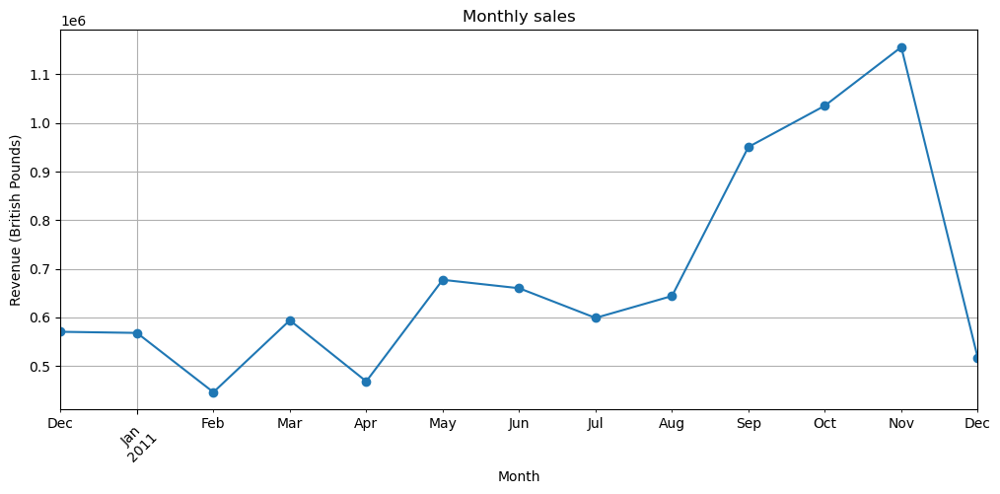

In [68]:
plt.figure(figsize=(12,5))
monthly_sale.plot(kind="line",marker="o")
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Revenue (British Pounds)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [69]:
#Weekly salesd
df_sale["Week"] = (
    df_sale["InvoiceDate"].dt.to_period("W").apply(lambda x : x.start_time)
)

In [70]:
df_sale.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue', 'RevenueTotal',
       'Month', 'Week'],
      dtype='object')

In [71]:
weekly_sale = (
    df_sale.groupby("Week")["RevenueTotal"].sum()
)

In [72]:
weekly_sale.head(10)

Week
2010-11-29    148627.97
2010-12-06    212619.13
2010-12-13    163116.12
2010-12-20     46059.51
2011-01-03    114636.80
2011-01-10    154344.85
2011-01-17    175452.23
2011-01-24    104861.00
2011-01-31    105955.81
2011-02-07     87827.94
Name: RevenueTotal, dtype: float64

In [73]:
weekly_growth=weekly_sale.pct_change()*100

In [74]:
weekly_growth.head(5)

Week
2010-11-29           NaN
2010-12-06     43.054588
2010-12-13    -23.282482
2010-12-20    -71.762748
2011-01-03    148.888449
Name: RevenueTotal, dtype: float64

In [75]:
weekly_report =pd.DataFrame({
    "Revenue":weekly_sale,
    "Growth_percentage":weekly_growth}
)

In [76]:
weekly_report.head(5)

,Revenue,Growth_percentage
Week,,
2010-11-29,148627.97,NaN
2010-12-06,212619.13,43.054588
2010-12-13,163116.12,-23.282482
2010-12-20,46059.51,-71.762748
2011-01-03,114636.80,148.888449


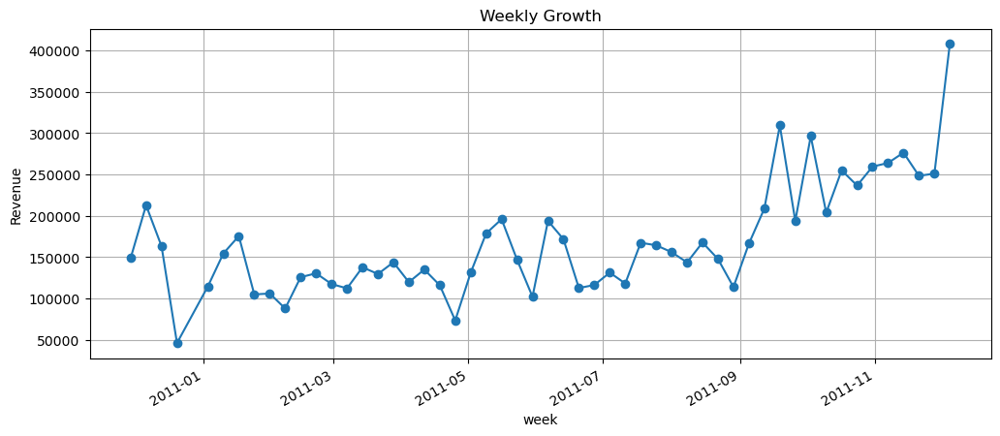

In [77]:
plt.figure(figsize=(12,5))
weekly_sale.plot(kind="line",marker="o")
plt.title("Weekly Growth")
plt.xlabel("week")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()

In [78]:
#Seasonal increase or decline.
df_sale.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue,RevenueTotal,Month,Week
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30,2010-12,2010-11-29
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29


In [79]:
df_sale["Month_no"]=(
    df_sale["Month"].dt.month
)
df_sale.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue,RevenueTotal,Month,Week,Month_no
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30,2010-12,2010-11-29,12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12


In [83]:
# Calculate revenue by calendar month
seasonal_sale=(
    df_sale.groupby("Month_no")["RevenueTotal"].sum()
)
seasonal_sale.head(10
                  )

Month_no
1      568101.310
2      446084.920
3      594081.760
4      468374.331
5      677355.150
6      660046.050
7      598962.901
8      644051.040
9      950690.202
10    1035642.450
Name: RevenueTotal, dtype: float64

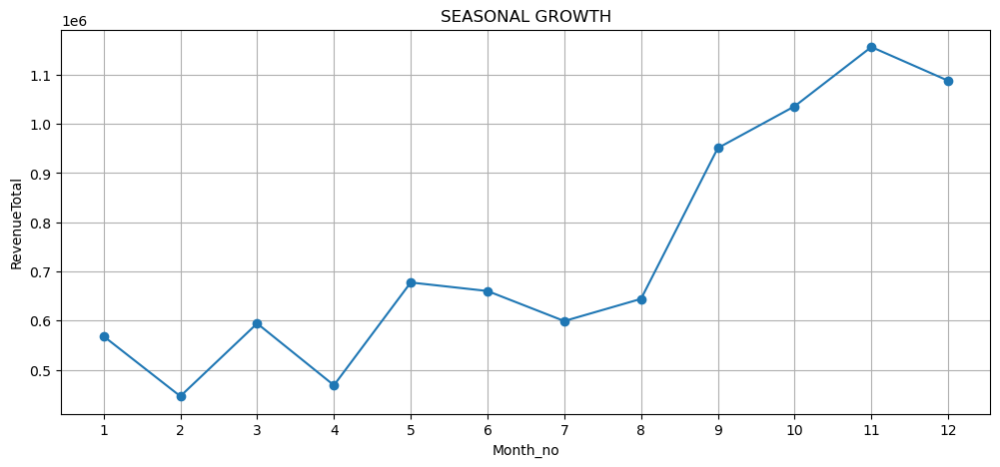

In [84]:
#chart
plt.figure(figsize=(12,5))
seasonal_sale.plot(kind="line", marker="o")
plt.title("SEASONAL GROWTH")
plt.xlabel("Month_no")
plt.ylabel("RevenueTotal")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

In [86]:
print(type(seasonal_sale))

<class 'pandas.core.series.Series'>


In [88]:
#highest and lowest sales months
print("Highest Sales Month:",seasonal_sale.max())
print("Lowest Sales Month:",seasonal_sale.min())

Highest Sales Month: 1156205.61
Lowest Sales Month: 446084.92


In [90]:
#Product performance over time
df_sale[["InvoiceDate", "Description", "RevenueTotal"]].head()

,InvoiceDate,Description,RevenueTotal
0,2010-12-01 08:26:00,WHITE HANGING HEART T-LIGHT HOLDER,15.30
1,2010-12-01 08:26:00,WHITE METAL LANTERN,20.34
2,2010-12-01 08:26:00,CREAM CUPID HEARTS COAT HANGER,22.00
3,2010-12-01 08:26:00,KNITTED UNION FLAG HOT WATER BOTTLE,20.34
4,2010-12-01 08:26:00,RED WOOLLY HOTTIE WHITE HEART.,20.34


In [92]:
product_monthly_sales = (
    df_sale.groupby(["Month", "Description"])["RevenueTotal"]
    .sum()
)

product_monthly_sales

Month    Description                     
2010-12   4 PURPLE FLOCK DINNER CANDLES       35.70
          OVAL WALL MIRROR DIAMANTE           89.55
          SET 2 TEA TOWELS I LOVE LONDON     746.35
         10 COLOUR SPACEBOY PEN              464.95
         12 COLOURED PARTY BALLOONS           31.20
                                              ...  
2011-12  ZINC T-LIGHT HOLDER STAR LARGE       81.88
         ZINC T-LIGHT HOLDER STARS SMALL     100.40
         ZINC WILLIE WINKIE  CANDLE STICK    117.09
         ZINC WIRE KITCHEN ORGANISER          63.20
         ZINC WIRE SWEETHEART LETTER TRAY     16.25
Name: RevenueTotal, Length: 30652, dtype: float64

In [93]:
# find top 5 product
top_products = (
    df_sale.groupby("Description")["RevenueTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_products

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
Name: RevenueTotal, dtype: float64

In [96]:
#product performance report
top_product_names = top_products.index

product_trend = (
    df_sale[df_sale["Description"].isin(top_product_names)]
    .pivot_table(
        index="Month",
        columns="Description",
        values="RevenueTotal",
        aggfunc="sum"
    )
)

product_trend

Description,JUMBO BAG RED RETROSPOT,MEDIUM CERAMIC TOP STORAGE JAR,"PAPER CRAFT , LITTLE BIRDIE",REGENCY CAKESTAND 3 TIER,WHITE HANGING HEART T-LIGHT HOLDER
Month,,,,,
2010-12,3619.20,NaN,NaN,17581.50,9602.05
2011-01,4542.75,77183.60,NaN,10765.50,14962.05
2011-02,5191.05,NaN,NaN,9559.65,4912.65
2011-03,8496.88,NaN,NaN,14784.65,5262.50
2011-04,4141.78,NaN,NaN,12721.50,9581.65
2011-05,6585.20,869.04,NaN,11503.60,10700.42
2011-06,6628.42,458.51,NaN,8216.35,4401.90
2011-07,5654.60,826.94,NaN,12174.00,8295.12
2011-08,9697.44,486.09,NaN,8921.70,5498.10


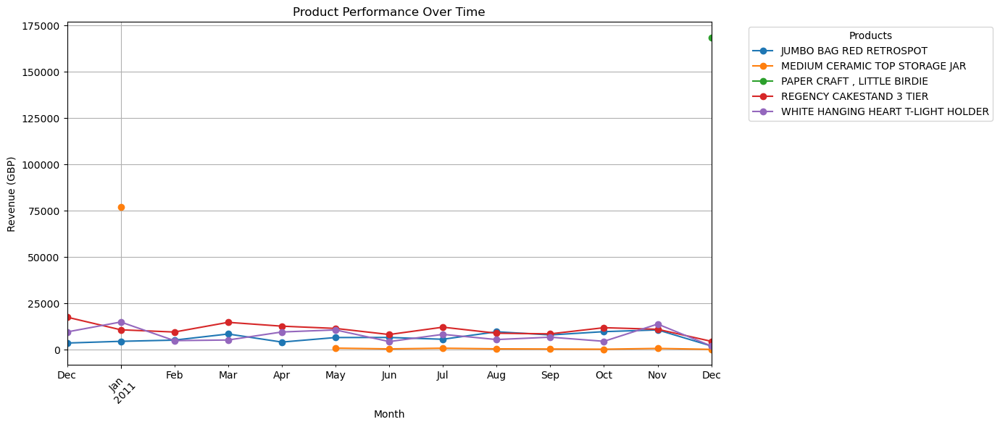

In [99]:


product_trend.plot(
    kind="line",
    figsize=(14, 6),
    marker="o"
)

plt.title("Product Performance Over Time")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend(title="Products", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

In [100]:
#Country-wise sales differences
country_sales = (
    df_sale.groupby("Country")["RevenueTotal"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: RevenueTotal, dtype: float64

In [101]:
#highest revenue-generating country
print("Top Country:", country_sales.idxmax())
print("Total Revenue:", country_sales.max())

Top Country: United Kingdom
Total Revenue: 7285024.644


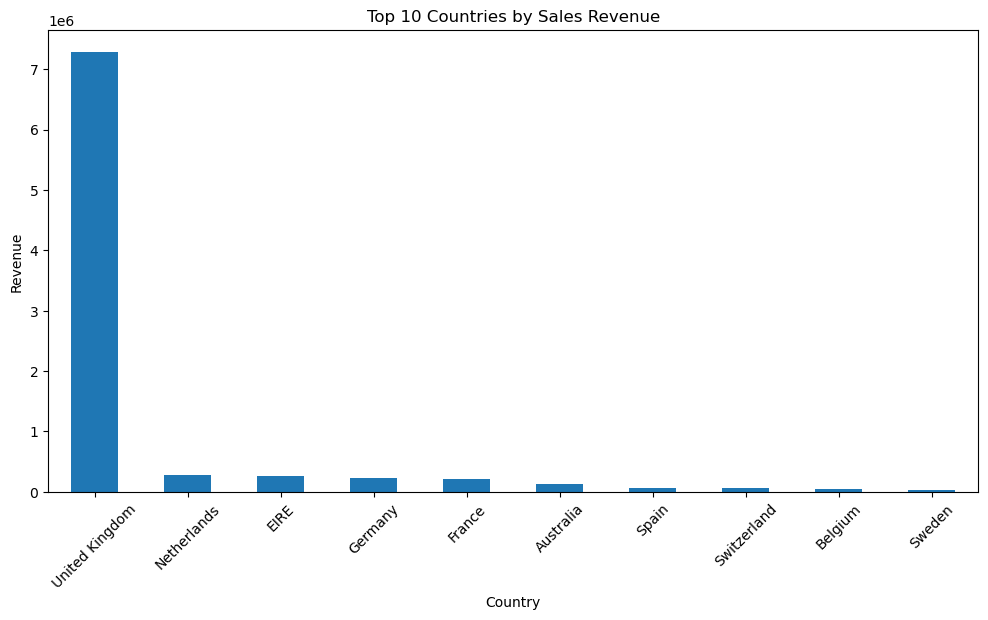

In [103]:
plt.figure(figsize=(12, 6))

country_sales.head(10).plot(kind="bar")

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

In [104]:
#Customer Insights
#Which customer segments order most frequently?

df_sale[["CustomerID", "InvoiceNo", "Country",
          "Description", "RevenueTotal"]].head()

,CustomerID,InvoiceNo,Country,Description,RevenueTotal
0,17850.0,536365,United Kingdom,WHITE HANGING HEART T-LIGHT HOLDER,15.30
1,17850.0,536365,United Kingdom,WHITE METAL LANTERN,20.34
2,17850.0,536365,United Kingdom,CREAM CUPID HEARTS COAT HANGER,22.00
3,17850.0,536365,United Kingdom,KNITTED UNION FLAG HOT WATER BOTTLE,20.34
4,17850.0,536365,United Kingdom,RED WOOLLY HOTTIE WHITE HEART.,20.34


In [106]:
#Remove records without CustomerID
df_customer = df_sale.dropna(
    subset=["CustomerID"]
).copy()

In [107]:
customer_orders = (
    df_customer.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

customer_orders.head(10)

CustomerID
12748.0    210
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     74
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

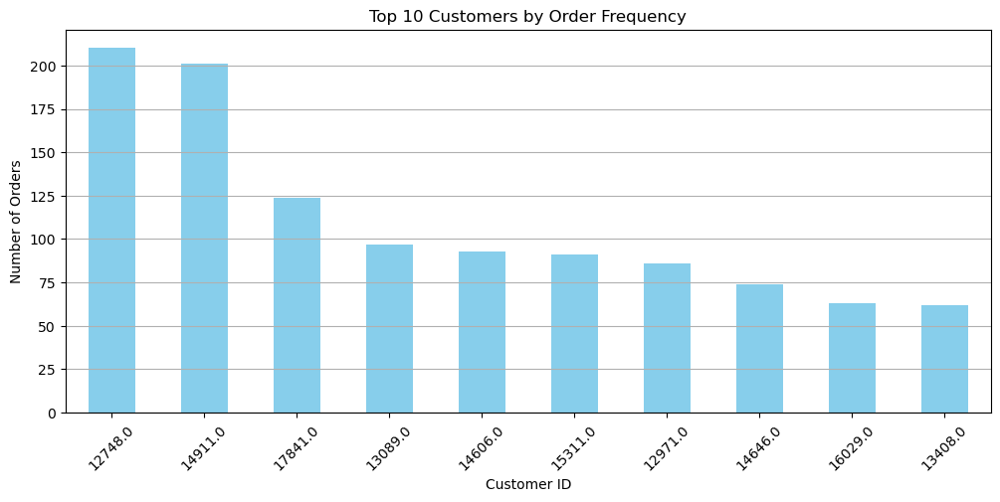

In [108]:
# chart

plt.figure(figsize=(12, 5))

customer_orders.head(10).plot(
    kind="bar",
    color="skyblue"
)

plt.title("Top 10 Customers by Order Frequency")
plt.xlabel("Customer ID")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [109]:
#repeat customers
customer_summary = (
    df_customer.groupby("CustomerID")
    .agg(
        total_orders=("InvoiceNo","nunique"),
        total_revenue=("RevenueTotal","sum")
    )
)
customer_summary.head(
    
)

,total_orders,total_revenue
CustomerID,,
12346.0,1,77183.60
12347.0,7,4310.00
12348.0,4,1797.24
12349.0,1,1757.55
12350.0,1,334.40


In [114]:
customer_summary["customer_type"]=(
    customer_summary["total_orders"].apply
    (lambda x :"Repeat customer" if x>1
    else "one time customer")
)

In [115]:
customer_summary.head()

,total_orders,total_revenue,customer_type
CustomerID,,,
12346.0,1,77183.60,one time customer
12347.0,7,4310.00,Repeat customer
12348.0,4,1797.24,Repeat customer
12349.0,1,1757.55,one time customer
12350.0,1,334.40,one time customer


In [116]:
#  repeat customer revenue
report_revenue = customer_summary.loc[
    customer_summary["customer_type"]=="Repeat customer",
    "total_revenue"
].sum()
print(" repeat customer revenue:",report_revenue)

 repeat customer revenue: 8273219.333000001


In [117]:
# total revenue
total_customer_revenue=customer_summary["total_revenue"].sum()
print("total_customer_revenue : ",total_customer_revenue)

total_customer_revenue :  8887208.894000001


In [118]:
#Calculate  percentage
one_time = total_revenue - report_revenue
one_time

np.float64(5300.090999999084)

In [119]:
#one_time_revenue = total_revenue - repeat_revenue

one_time_percentage = (
    one_time / total_revenue
) * 100

print("One-Time Customer Revenue:", one_time)

print("One-Time Customer Contribution:",
      round(one_time_percentage, 2), "%")

One-Time Customer Revenue: 5300.090999999084
One-Time Customer Contribution: 0.06 %


In [120]:
#Which region or city shows high order density?
country_order = (
    df_sale.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)

)
country_order.head()

Country
United Kingdom    16649
Germany             457
France              389
EIRE                260
Belgium              98
Name: InvoiceNo, dtype: int64

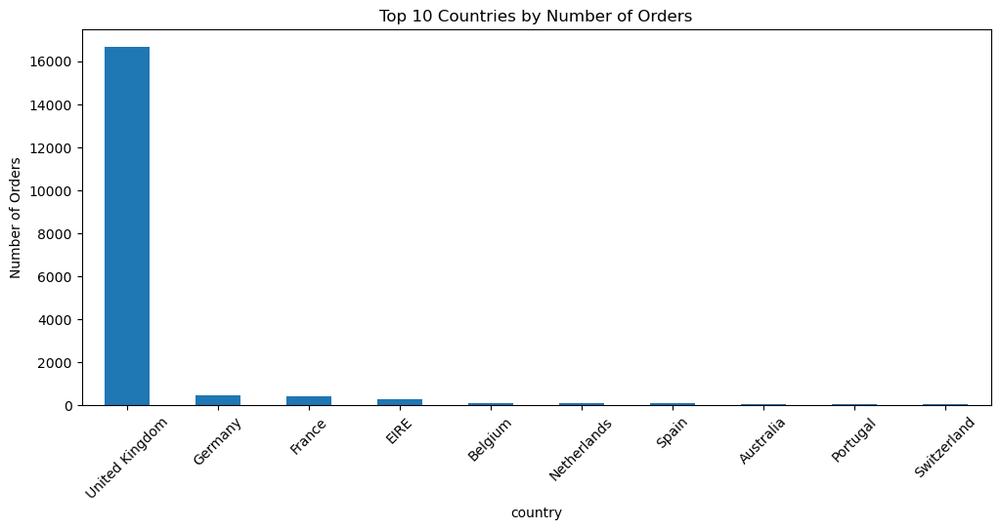

In [122]:
# chart
plt.figure(figsize=(12,5))
country_order.head(10).plot(kind="bar")
plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("country")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [126]:
df_sale.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue,RevenueTotal,Month,Week,Month_no
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30,2010-12,2010-11-29,12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,22.00,2010-12,2010-11-29,12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12


In [124]:
df_clean.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue'],
      dtype='object')

In [127]:
# Are some product categories preferred by specific customer groups?
'''customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

customer_summary = (
    customer_df.groupby("CustomerID")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Revenue=("Revenue", "sum")
    )
)

customer_summary["Customer_Type"] = customer_summary[
    "Total_Orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)'''
#Connect customer groups with products
customer_product  = df_customer.merge(
    customer_summary[["customer_type"]],
    on="CustomerID",
    how="left"
)


In [128]:
#popular products for each group
grp_product_sale = (
    customer_product.groupby(
        ["customer_type","Description"]
    )["Quantity"].sum()
    .reset_index()
)
grp_product_sale =grp_product_sale.sort_values(
    ["customer_type","Quantity"],
    ascending=[True,False]
)
grp_product_sale.groupby("customer_type").head(10)

,customer_type,Description,Quantity
2292,Repeat customer,"PAPER CRAFT , LITTLE BIRDIE",80995
3752,Repeat customer,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48499
1745,Repeat customer,JUMBO BAG RED RETROSPOT,44428
3664,Repeat customer,WHITE HANGING HEART T-LIGHT HOLDER,35172
215,Repeat customer,ASSORTED COLOUR BIRD ORNAMENT,33724
2242,Repeat customer,PACK OF 72 RETROSPOT CAKE CASES,31351
2572,Repeat customer,POPCORN HOLDER,30283
2628,Repeat customer,RABBIT NIGHT LIGHT,26866
2208,Repeat customer,PACK OF 12 LONDON TISSUES,25017
2023,Repeat customer,MINI PAINT SET VINTAGE,24960


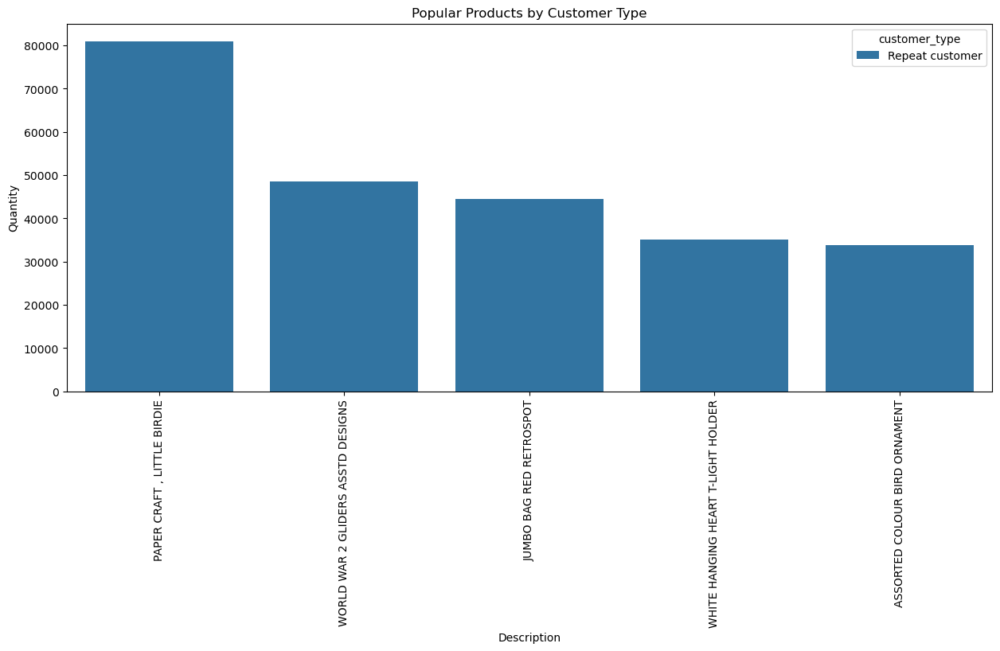

In [130]:
plt.figure(figsize=(15,6))
sns.barplot(
    data=grp_product_sale.head(5),x="Description", y= "Quantity", hue="customer_type"
)

plt.title("Popular Products by Customer Type")
plt.xticks(rotation=90)
plt.show()

In [131]:
#Which month recorded the highest sales?
highest_sales_month = monthly_sale.idxmax()
highest_sales = monthly_sale.max()

print("Highest Sales Month:", highest_sales_month)
print("Highest Sales Revenue:", round(highest_sales, 2))

Highest Sales Month: 2011-11
Highest Sales Revenue: 1156205.61


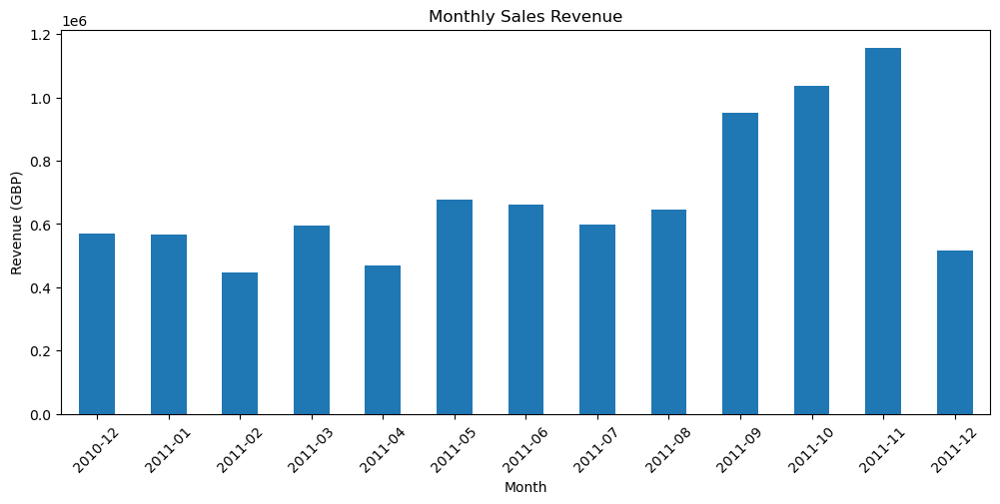

In [132]:
plt.figure(figsize=(12, 5))

monthly_sale.plot(kind="bar")

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.show()

In [134]:
#Which product categories contribute the most revenue?
product_revenue = (
    df_sale.groupby("Description")["RevenueTotal"]
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: RevenueTotal, dtype: float64

In [135]:
total_revenue = df_sale["RevenueTotal"].sum()

product_contribution = (
    product_revenue / total_revenue
) * 100

product_contribution.head(10).round(2)

Description
PAPER CRAFT , LITTLE BIRDIE           1.90
REGENCY CAKESTAND 3 TIER              1.60
WHITE HANGING HEART T-LIGHT HOLDER    1.13
JUMBO BAG RED RETROSPOT               0.96
MEDIUM CERAMIC TOP STORAGE JAR        0.92
POSTAGE                               0.88
PARTY BUNTING                         0.77
ASSORTED COLOUR BIRD ORNAMENT         0.63
Manual                                0.60
RABBIT NIGHT LIGHT                    0.58
Name: RevenueTotal, dtype: float64

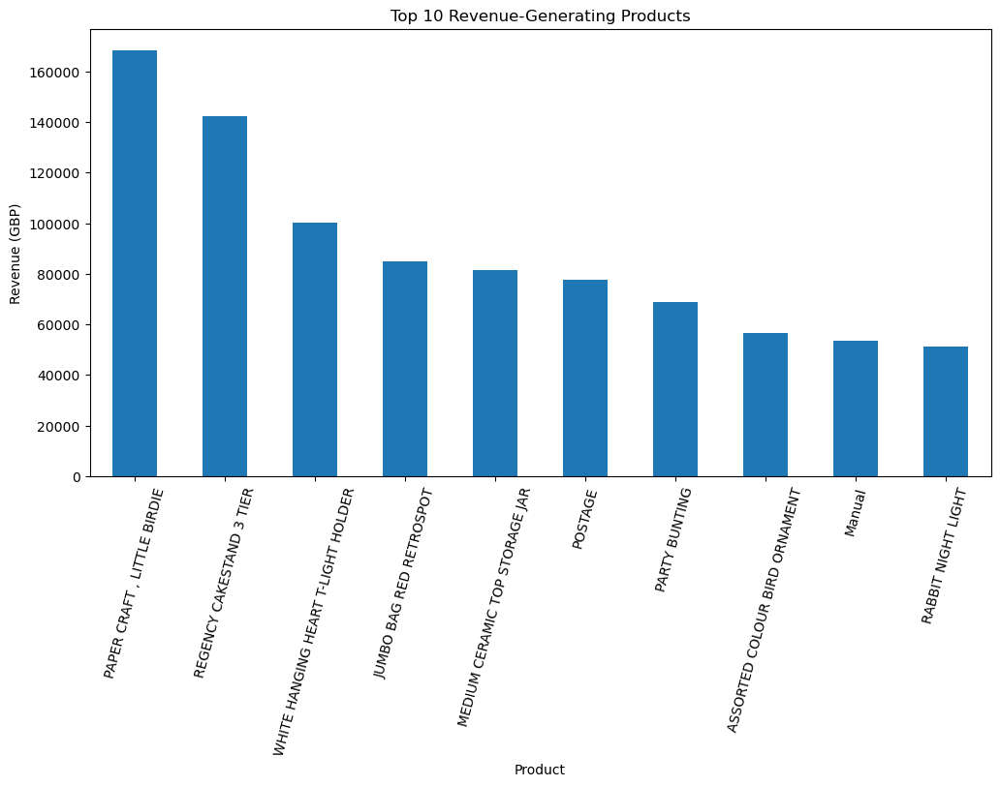

In [136]:
top_10_products = product_revenue.head(10)

plt.figure(figsize=(12, 6))

top_10_products.plot(kind="bar")

plt.title("Top 10 Revenue-Generating Products")
plt.xlabel("Product")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=75)
plt.show()

In [137]:
df_sale["RevenueTotal"].describe()

count    392732.000000
mean         22.629195
std         311.083465
min           0.000000
25%           4.950000
50%          12.390000
75%          19.800000
max      168469.600000
Name: RevenueTotal, dtype: float64

In [139]:
#Is customer purchase behavior evenly distributed or heavily skewed?
customer_purchase = (
    df_sale.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Revenue=("RevenueTotal", "sum")
    )
)

customer_purchase.head()

,Total_Orders,Total_Revenue
CustomerID,,
12346.0,1,77183.60
12347.0,7,4310.00
12348.0,4,1797.24
12349.0,1,1757.55
12350.0,1,334.40


In [140]:
customer_purchase["Total_Revenue"].describe()

count      4339.000000
mean       2048.215924
std        8984.248352
min           0.000000
25%         306.455000
50%         668.560000
75%        1660.315000
max      280206.020000
Name: Total_Revenue, dtype: float64

In [141]:
top_customers = customer_purchase.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

total_customer_revenue = customer_purchase["Total_Revenue"].sum()

top_10_revenue = top_customers["Total_Revenue"].sum()

top_10_percentage = (
    top_10_revenue / total_customer_revenue
) * 100

print("Top 10 Customer Revenue:", round(top_10_revenue, 2))

print("Top 10 Customer Contribution:",
      round(top_10_percentage, 2), "%")

Top 10 Customer Revenue: 1537659.21
Top 10 Customer Contribution: 17.3 %


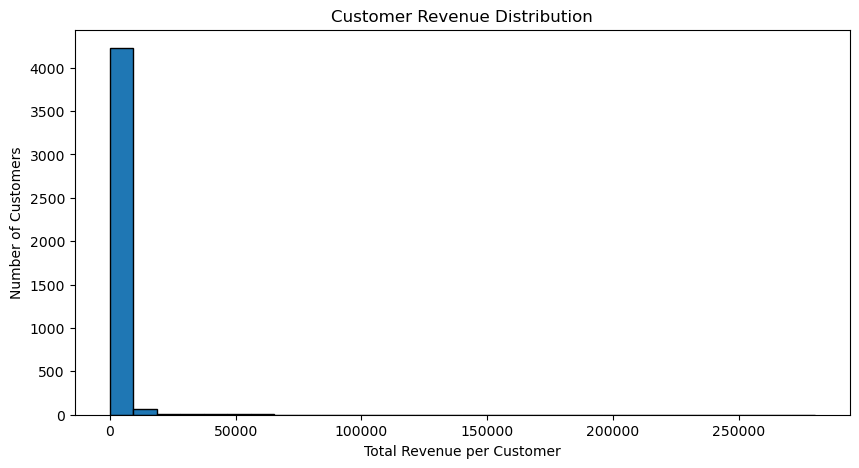

In [142]:


plt.figure(figsize=(10, 5))

plt.hist(
    customer_purchase["Total_Revenue"],
    bins=30,
    edgecolor="black"
)

plt.title("Customer Revenue Distribution")
plt.xlabel("Total Revenue per Customer")
plt.ylabel("Number of Customers")

plt.show()

In [150]:
#KPI summary table (key performance indicators)

# total revenue
total_revenue = df_sale["RevenueTotal"].sum()

#total order
total_order = df_sale["InvoiceNo"].nunique()
# total customer 
total_customer = df_sale["CustomerID"].nunique()

# total products
total_product = df_sale["Description"].nunique()

#avg order value
avg_order = total_revenue/ total_order

#highest revenue product
top_product = (
    df_sale.groupby("Description")["RevenueTotal"].sum().idxmax()
)


# hightest sale of month
hightest_monthly_sale= monthly_sale.idxmax()


#repeat customer 
cust_order = (
    df_sale.dropna(
        subset = ["CustomerID"]
    ).groupby("CustomerID")["InvoiceNo"].nunique()
)

repeat_customer=(cust_order > 1).sum()

# Create KPI Table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Order",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Top Revenue-Generating Product",
        "Highest Sales Month",
        "Repeat Customers"
    ],
    "Value": [
        round(total_revenue, 2),
        total_order,
        total_customer,
        total_product,
        round(avg_order, 2),
        top_product,
        str(hightest_monthly_sale),
        repeat_customer
    ]
})

kpi_summary



,KPI,Value
0,Total Revenue,8887208.89
1,Total Order,18536
2,Total Customers,4339
3,Total Products,3877
4,Average Order Value,479.46
5,Top Revenue-Generating Product,"PAPER CRAFT , LITTLE BIRDIE"
6,Highest Sales Month,2011-11
7,Repeat Customers,2845


In [151]:
kpi_summary.to_excel(
    "KPI_Summary.xlsx",
    index=False
)

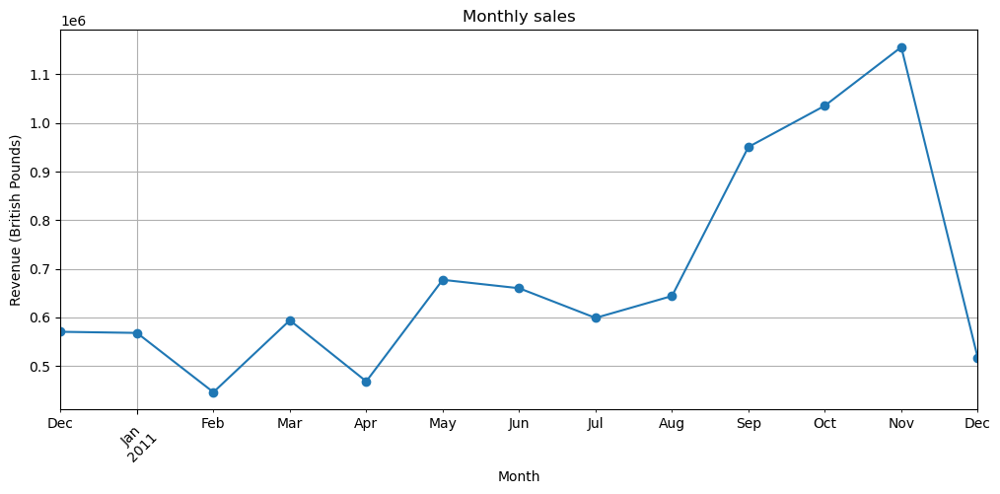

In [152]:
 # At least one trend-based interpretation.
plt.figure(figsize=(12,5))
monthly_sale.plot(kind="line",marker="o")
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Revenue (British Pounds)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [154]:
df_sale.columns


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue', 'RevenueTotal',
       'Month', 'Week', 'Month_no'],
      dtype='object')

In [158]:
customer_insights = (
    df_sale.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Revenue=("RevenueTotal", "sum")
    )
)

customer_insights.head()


customer_insights["Customer_Type"] = customer_insights[
    "Total_Orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

customer_insights.head()


repeat_revenue = customer_insights.loc[
    customer_insights["Customer_Type"] == "Repeat Customer",
    "Total_Revenue"
].sum()

one_time_revenue = customer_insights.loc[
    customer_insights["Customer_Type"] == "One-Time Customer",
    "Total_Revenue"
].sum()

total_customer_revenue = customer_insights["Total_Revenue"].sum()

repeat_percentage = (repeat_revenue / total_customer_revenue) * 100

one_time_percentage = (one_time_revenue / total_customer_revenue) * 100

print("Repeat Customer Contribution:", round(repeat_percentage, 2), "%")
print("One-Time Customer Contribution:", round(one_time_percentage, 2), "%")


Repeat Customer Contribution: 93.09 %
One-Time Customer Contribution: 6.91 %


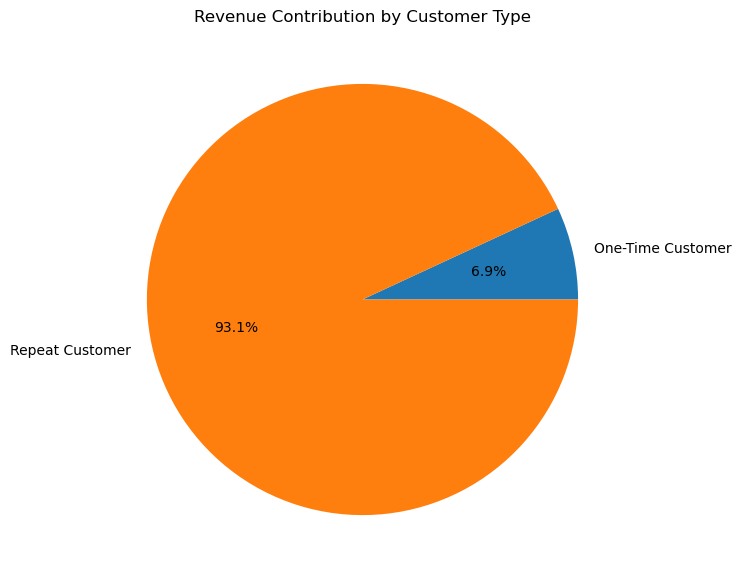

In [159]:
customer_revenue = customer_insights.groupby(
    "Customer_Type"
)["Total_Revenue"].sum()

customer_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Revenue Contribution by Customer Type")
plt.ylabel("")
plt.show()

In [160]:
#  Visualization Challenge
# 1 Revenue by category.
category_revenue = (
    df_sale.groupby("Description")["RevenueTotal"]
    .sum()
    .sort_values(ascending=False)
)
category_revenue

Description
PAPER CRAFT , LITTLE BIRDIE           168469.600
REGENCY CAKESTAND 3 TIER              142264.750
WHITE HANGING HEART T-LIGHT HOLDER    100392.100
JUMBO BAG RED RETROSPOT                85040.540
MEDIUM CERAMIC TOP STORAGE JAR         81416.730
                                         ...    
PURPLE FRANGIPANI HAIRCLIP                 0.850
VINTAGE BLUE TINSEL REEL                   0.840
SET 12 COLOURING PENCILS DOILEY            0.650
HEN HOUSE W CHICK IN NEST                  0.420
PADS TO MATCH ALL CUSHIONS                 0.003
Name: RevenueTotal, Length: 3877, dtype: float64

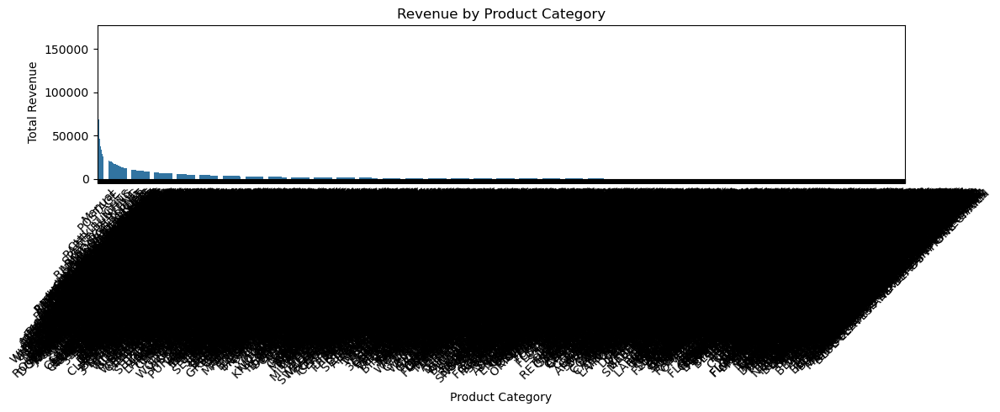

In [163]:
plt.figure(figsize=(12,5))
sns.barplot(x=category_revenue.index,y=category_revenue.values)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [164]:
category_percentage = (
    category_revenue / category_revenue.sum()
) * 100

category_percentage.round(2)

Description
PAPER CRAFT , LITTLE BIRDIE           1.90
REGENCY CAKESTAND 3 TIER              1.60
WHITE HANGING HEART T-LIGHT HOLDER    1.13
JUMBO BAG RED RETROSPOT               0.96
MEDIUM CERAMIC TOP STORAGE JAR        0.92
                                      ... 
PURPLE FRANGIPANI HAIRCLIP            0.00
VINTAGE BLUE TINSEL REEL              0.00
SET 12 COLOURING PENCILS DOILEY       0.00
HEN HOUSE W CHICK IN NEST             0.00
PADS TO MATCH ALL CUSHIONS            0.00
Name: RevenueTotal, Length: 3877, dtype: float64

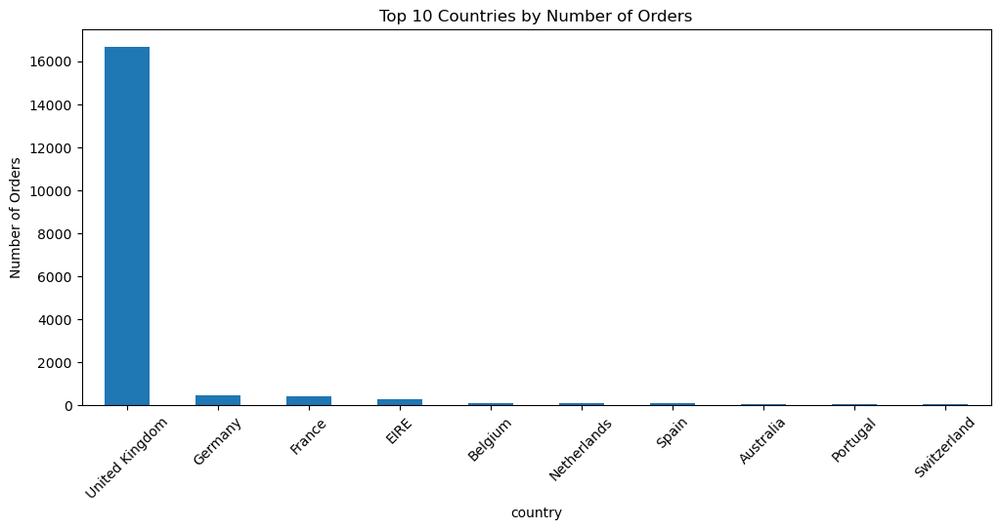

In [165]:
# Orders by city.
# chart reff 122 line
plt.figure(figsize=(12,5))
country_order.head(10).plot(kind="bar")
plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("country")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

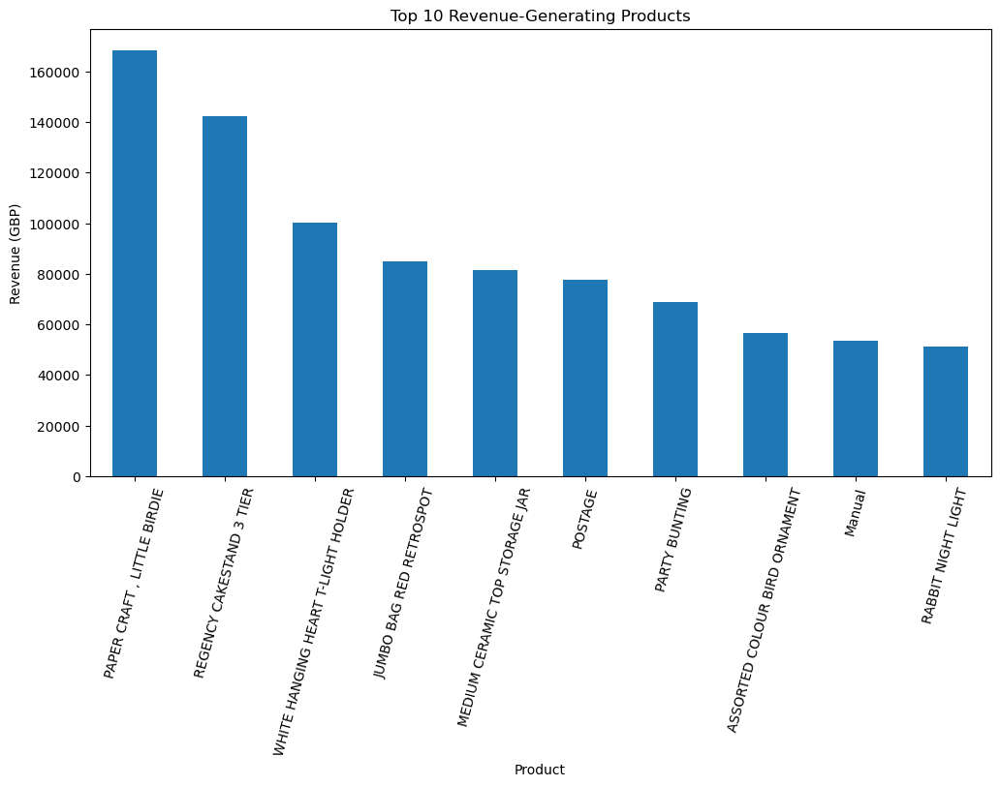

In [166]:
# top 10 product by unit sold reff line 135
top_10_products = product_revenue.head(10)

plt.figure(figsize=(12, 6))

top_10_products.plot(kind="bar")

plt.title("Top 10 Revenue-Generating Products")
plt.xlabel("Product")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=75)
plt.show()

In [173]:
# Remove cancelled invoices
df_sale["order_status"]=df_sale["InvoiceNo"].astype(str).apply(
   
        lambda x: "cancelled"if x.startswith("C") else  "non-cancelled")
    

In [175]:
order_status_counts = (
    df_sale.groupby("order_status")["InvoiceNo"]
    .nunique()
)

print(order_status_counts)

order_status
non-cancelled    18536
Name: InvoiceNo, dtype: int64


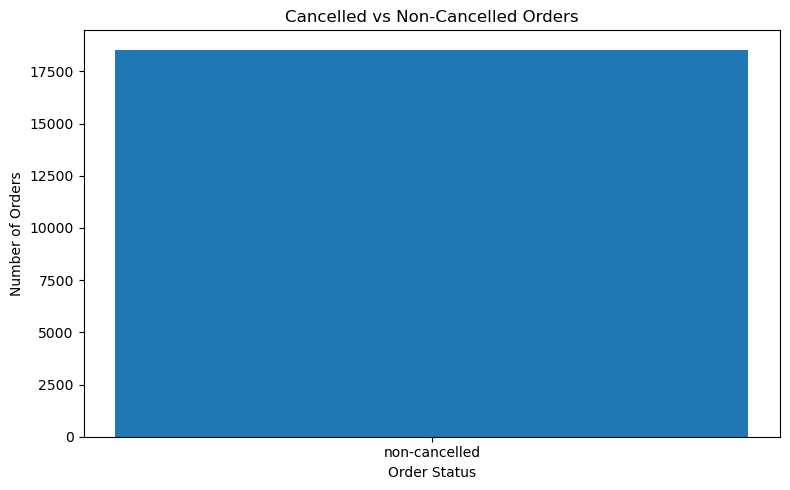

In [176]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    order_status_counts.index,
    order_status_counts.values
)

plt.title("Cancelled vs Non-Cancelled Orders")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

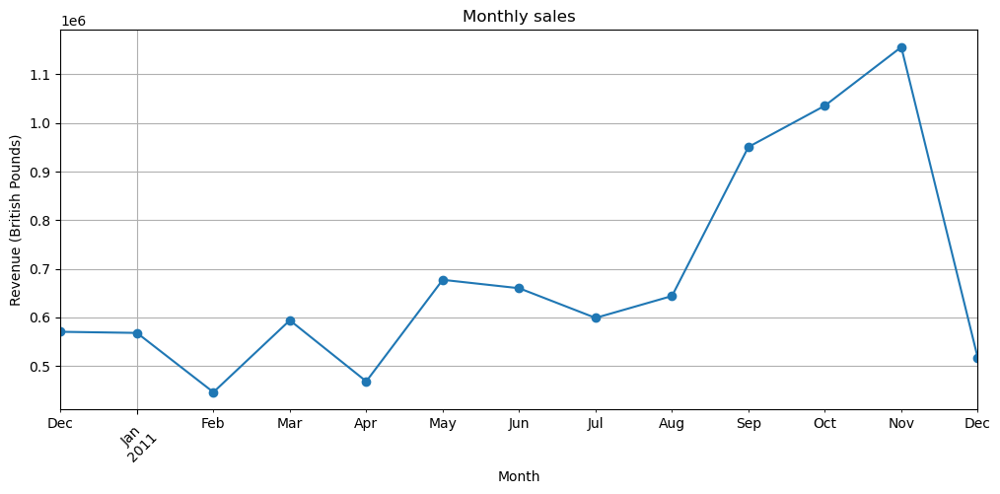

In [177]:
#Monthly sales trend. reff line
 # At least one trend-based interpretation.
plt.figure(figsize=(12,5))
monthly_sale.plot(kind="line",marker="o")
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Revenue (British Pounds)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [178]:
# Weekly order count trend.
# Group orders by week and count unique invoices
weekly_orders = (
    df_sale.groupby("Week")["InvoiceNo"]
    .nunique()
    .sort_index()
)

print(weekly_orders)

Week
2010-11-29    402
2010-12-06    489
2010-12-13    401
2010-12-20    108
2011-01-03    224
2011-01-10    233
2011-01-17    206
2011-01-24    267
2011-01-31    272
2011-02-07    198
2011-02-14    267
2011-02-21    267
2011-02-28    267
2011-03-07    269
2011-03-14    304
2011-03-21    299
2011-03-28    320
2011-04-04    295
2011-04-11    344
2011-04-18    248
2011-04-25    193
2011-05-02    343
2011-05-09    387
2011-05-16    429
2011-05-23    327
2011-05-30    238
2011-06-06    373
2011-06-13    341
2011-06-20    304
2011-06-27    255
2011-07-04    310
2011-07-11    305
2011-07-18    325
2011-07-25    324
2011-08-01    302
2011-08-08    256
2011-08-15    309
2011-08-22    349
2011-08-29    254
2011-09-05    379
2011-09-12    347
2011-09-19    447
2011-09-26    428
2011-10-03    472
2011-10-10    429
2011-10-17    429
2011-10-24    502
2011-10-31    510
2011-11-07    608
2011-11-14    669
2011-11-21    595
2011-11-28    633
2011-12-05    484
Name: InvoiceNo, dtype: int64


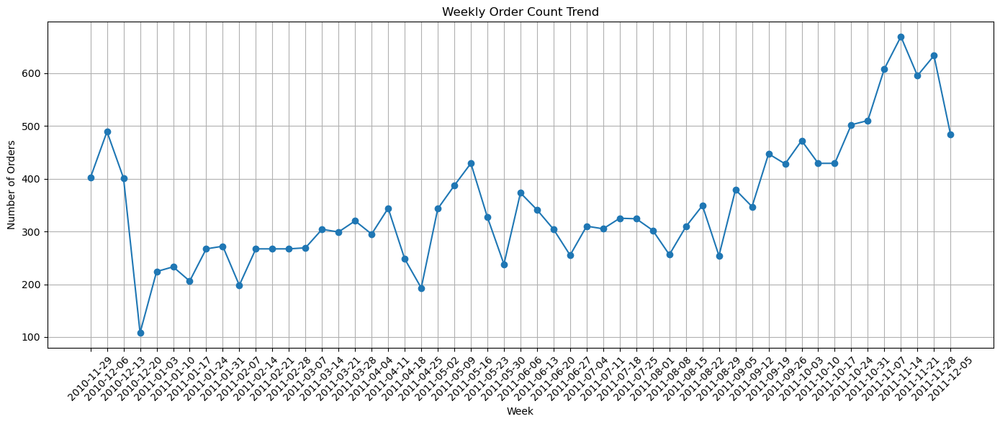

In [179]:


plt.figure(figsize=(14, 6))

plt.plot(
    weekly_orders.index.astype(str),
    weekly_orders.values,
    marker="o"
)

plt.title("Weekly Order Count Trend")
plt.xlabel("Week")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [180]:
# Revenue trend by category across months.
# Calculate monthly revenue by category
monthly_category_revenue = (
    df_sale.groupby(["Month", "Description"])["RevenueTotal"]
    .sum()
    .reset_index()
)

# Convert data into chart format
category_trend = monthly_category_revenue.pivot(
    index="Month",
    columns="Description",
    values="RevenueTotal"
).fillna(0)

display(category_trend)

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
Month,,,,,,,,,,,,,,,,,,,,,
2010-12,35.70,0.00,0.00,0.00,0.00,0.0,89.55,0.00,746.35,0.00,...,0.0,0.00,0.00,0.00,0.0,0.00,16.95,147.90,0.0,0.00
2011-01,5.10,0.00,0.00,0.00,0.00,0.0,119.40,0.00,1107.20,0.00,...,0.0,0.00,0.00,0.00,0.0,0.00,84.75,83.30,0.0,0.00
2011-02,2.55,0.00,0.00,0.00,0.00,0.0,39.80,0.00,603.10,0.00,...,0.0,0.00,0.00,0.00,0.0,0.00,16.95,113.90,0.0,0.00
2011-03,0.00,0.00,0.00,0.00,0.00,0.0,49.75,0.00,2683.55,2111.10,...,0.0,0.00,0.00,0.00,0.0,0.00,0.00,45.05,0.0,0.00
2011-04,17.85,0.00,0.00,0.00,0.00,0.0,159.20,0.00,991.45,663.90,...,0.0,0.00,141.36,51.30,0.0,249.12,16.95,97.75,0.0,97.71
2011-05,7.65,0.00,0.00,0.00,0.00,0.0,194.30,0.00,888.05,753.60,...,10.0,32.37,112.50,383.64,11.4,1026.81,16.95,85.00,20.8,22.50
2011-06,5.10,0.00,0.00,0.00,0.00,0.0,79.60,0.00,171.25,518.40,...,0.0,0.00,30.00,163.38,0.0,290.28,0.00,112.20,0.0,26.78
2011-07,7.65,0.00,83.75,0.00,0.00,0.0,79.60,0.00,0.00,339.00,...,0.0,17.43,167.31,102.60,11.4,309.52,0.00,87.55,31.2,15.00
2011-08,2.55,30.00,1079.25,0.00,0.00,0.0,19.90,85.00,0.00,242.25,...,0.0,9.96,127.50,299.09,0.0,375.16,0.00,124.10,10.4,3.75


In [184]:


plt.figure(figsize=(14, 6))

for category in category_trend.columns:
    plt.plot(
        category_trend.index.astype(str),
        category_trend[category],
        marker="o",
        label=category
    )

plt.title("Revenue Trend by Category Across Months")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.legend(title="Category")
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\prajw\AppData\Local\Temp\ipykernel_19388\3950022039.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\prajw\AppData\Local\Temp\ipykernel_19388\3950022039.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


In [185]:
# Pie Charts
# Sales contribution by payment mode.
# Calculate revenue by country
country_revenue = (
    df_sale.groupby("Country")["RevenueTotal"]
    .sum()
    .sort_values(ascending=False)
)

# Select top 5 countries and group the rest as Others
top_5 = country_revenue.head(5)

other_revenue = country_revenue.iloc[5:].sum()

pie_data = pd.concat([
    top_5,
    pd.Series({"Others": other_revenue})
])

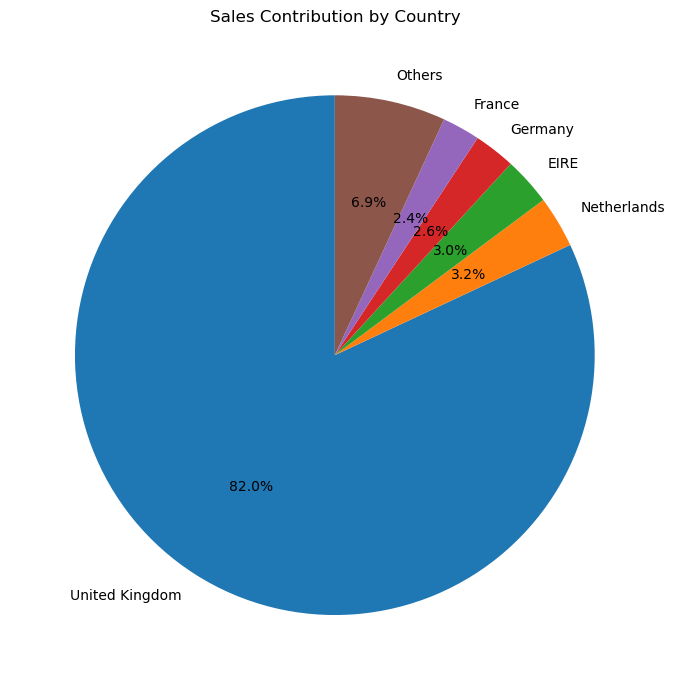

In [186]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Contribution by Country")

plt.tight_layout()
plt.show()

In [190]:
#Share of orders by category when category count is low. 
category_orders = (
    df_sale.groupby("Description")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print(category_orders)

Description
WHITE HANGING HEART T-LIGHT HOLDER     1971
REGENCY CAKESTAND 3 TIER               1704
JUMBO BAG RED RETROSPOT                1600
PARTY BUNTING                          1380
ASSORTED COLOUR BIRD ORNAMENT          1375
                                       ... 
FIRE POLISHED GLASS BRACELET RED          1
ROSE PENDANT TRIPLE SHELL NECKLACE        1
FIRE POLISHED GLASS BRACELET MONTAN       1
CAT WITH SUNGLASSES BLANK CARD            1
DOLPHIN WINDMILL                          1
Name: InvoiceNo, Length: 3877, dtype: int64


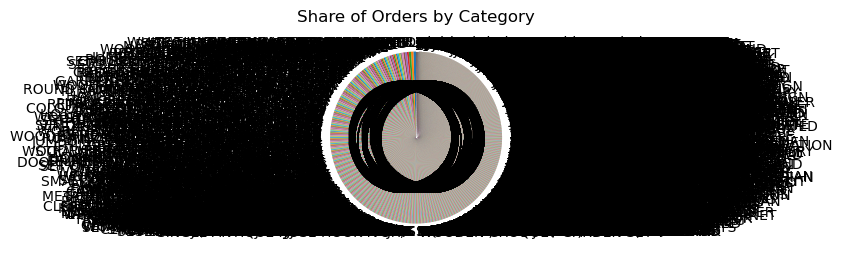

In [191]:


plt.figure(figsize=(8, 8))

plt.pie(
    category_orders.values,
    labels=category_orders.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of Orders by Category")

plt.tight_layout()
plt.show()

In [200]:
#Delivery status share.
 # ref line173 
order_percentage = (
    order_status_counts / order_status_counts.sum()
) * 100

print(order_percentage.round(2))

order_status
non-cancelled    100.0
Name: InvoiceNo, dtype: float64


In [199]:
df_sale.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue', 'RevenueTotal',
       'Month', 'Week', 'Month_no', 'order_status'],
      dtype='object')

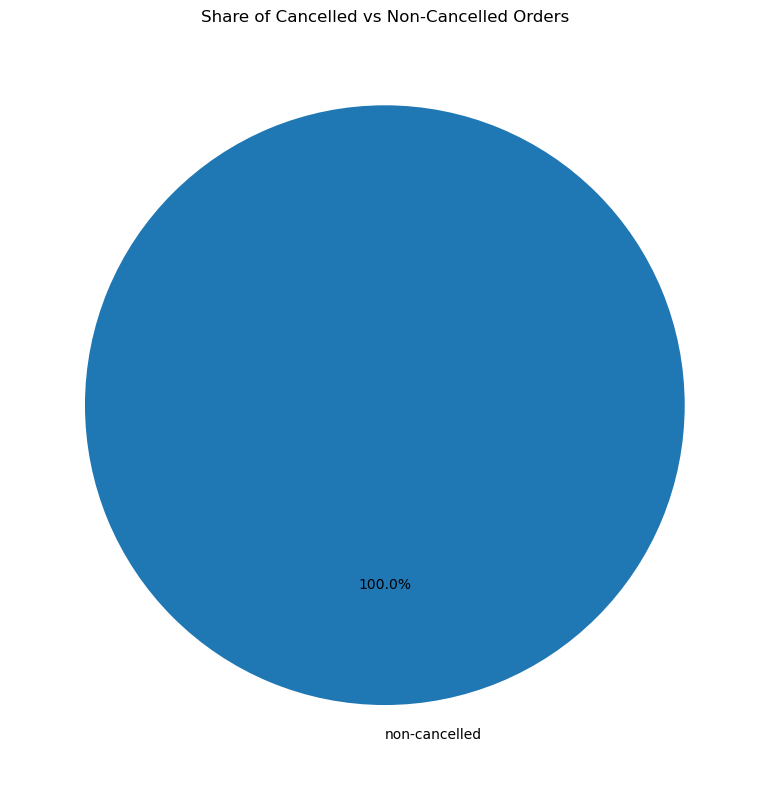

In [204]:


plt.figure(figsize=(8, 8))

plt.pie(
    order_status_counts.values,
    labels=order_status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of Cancelled vs Non-Cancelled Orders")

plt.tight_layout()
plt.show()

In [207]:
df_sale.to_excel("cleaned_online_retail_data.xlsx",index=False)

In [208]:
df_sale

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalRevenue,RevenueTotal,Month,Week,Month_no,order_status
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30,2010-12,2010-11-29,12,non-cancelled
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12,non-cancelled
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,22.00,2010-12,2010-11-29,12,non-cancelled
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12,non-cancelled
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34,2010-12,2010-11-29,12,non-cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,10.20,2011-12,2011-12-05,12,non-cancelled
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,12.60,2011-12,2011-12-05,12,non-cancelled
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,16.60,2011-12,2011-12-05,12,non-cancelled
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,16.60,2011-12,2011-12-05,12,non-cancelled


In [209]:
df_sale.columns


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalRevenue', 'RevenueTotal',
       'Month', 'Week', 'Month_no', 'order_status'],
      dtype='object')